In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import os
import warnings

warnings.filterwarnings("ignore")

In [43]:
# =============================================================================
# Matplotlib Configuration
# =============================================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "figure.dpi": 130,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

# =============================================================================
# Project Paths
# =============================================================================

BASE_PATH = r"C:\Users\jyoti\OneDrive\Desktop\JJD\Data\New_Analysis"

RESULT_DIR = os.path.join(BASE_PATH, "RESULT_DIR")

IMAGE_DIR = os.path.join(BASE_PATH, "images")

IMAGE_SUBDIRS = {
    "wifi": "wifi",
    "mobile": "mobile",
    "lan": "lan",
    "combined": "combined",
}

for folder in IMAGE_SUBDIRS.values():
    os.makedirs(os.path.join(IMAGE_DIR, folder), exist_ok=True)

# =============================================================================
# Plot Saving Utility
# =============================================================================

def save_plot(filename, category="combined"):
    """
    Save matplotlib figures into the correct output directory.

    Parameters
    ----------
    filename : str
        Output filename.
    category : str
        wifi / mobile / lan / combined
    """

    folder = IMAGE_SUBDIRS.get(category.lower(), "combined")

    path = os.path.join(IMAGE_DIR, folder, filename)

    plt.savefig(path,
                dpi=300,
                bbox_inches="tight")

    return path

# =============================================================================
# TLS Configurations
# =============================================================================

CONFIG_ORDER = [
    "classical",
    "mlkem_mldsa",
    "hybrid",
    "mlkem_slhdsa",
]

CONFIG_LABELS = {

    "classical":
        "Classical\nTLS 1.3",

    "mlkem_mldsa":
        "ML-KEM-768\n+\nML-DSA-65",

    "hybrid":
        "Hybrid\nECDHE + ML-KEM",

    "mlkem_slhdsa":
        "ML-KEM-768\n+\nSLH-DSA-128s",
}

CONFIG_LABELS_FLAT = {

    "classical":
        "Classical TLS 1.3",

    "mlkem_mldsa":
        "ML-KEM-768 + ML-DSA-65",

    "hybrid":
        "Hybrid (ECDHE + ML-KEM)",

    "mlkem_slhdsa":
        "ML-KEM-768 + SLH-DSA-128s",
}

# =============================================================================
# Consistent Color Palette
# =============================================================================

CONFIG_COLORS = {

    "classical": "#90A4AE",      # Grey
    "mlkem_mldsa": "#1E88E5",    # Blue
    "hybrid": "#43A047",         # Green
    "mlkem_slhdsa": "#E53935",   # Red
}

NETWORK_PALETTE = {

    "LAN": "#1565C0",
    "wifi": "#2E7D32",
    "hotspot": "#BF360C",
}

# =============================================================================
# Network Ordering
# =============================================================================

NETWORK_ORDER = [
    "LAN",
    "wifi",
    "hotspot",
]

In [45]:
# =============================================================================
# Load Complete Benchmark Dataset
# =============================================================================

import os
import pandas as pd

RESULT_DIR = os.path.join(BASE_PATH, "results")

frames = []

for date in sorted(os.listdir(RESULT_DIR)):

    date_path = os.path.join(RESULT_DIR, date)

    if not os.path.isdir(date_path):
        continue

    for batch in sorted(os.listdir(date_path)):

        batch_path = os.path.join(date_path, batch)

        if not os.path.isdir(batch_path):
            continue

        for network in sorted(os.listdir(batch_path)):

            network_path = os.path.join(batch_path, network)

            if not os.path.isdir(network_path):
                continue

            result_file = os.path.join(network_path, "results.csv")

            if not os.path.exists(result_file):
                continue

            df_tmp = pd.read_csv(
                result_file,
                na_values=[
                    "",
                    " ",
                    "NA",
                    "N/A",
                    "None",
                    "null",
                    "NULL",
                    "-",
                    "--"
                ]
            )

            # -----------------------------------------------------------------
            # Metadata
            # -----------------------------------------------------------------

            df_tmp["date"] = date
            df_tmp["batch"] = batch
            df_tmp["network"] = network

            frames.append(df_tmp)

# =============================================================================
# Combine
# =============================================================================

df = pd.concat(frames, ignore_index=True)

# =============================================================================
# Convert Timestamp Columns
# =============================================================================

possible_timestamp_columns = [
    "timestamp",
    "time",
    "datetime",
    "collection_time"
]

for col in possible_timestamp_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# =============================================================================
# Automatically Convert Numeric Columns
# =============================================================================

# Columns that should remain as text
text_columns = {
    "config",
    "network",
    "date",
    "batch",
    "timestamp",
    "time",
    "datetime",
    "collection_time",
}

for col in df.columns:

    if col in text_columns:
        continue

    if df[col].dtype == object:

        # Remove common units/symbols if present
        cleaned = (
            df[col]
            .astype(str)
            .str.replace("ms", "", regex=False)
            .str.replace("KB", "", regex=False)
            .str.replace("bytes", "", regex=False)
            .str.replace(",", "", regex=False)
            .str.strip()
        )

        numeric = pd.to_numeric(
            cleaned,
            errors="coerce"
        )

        # Convert only if most values are numeric
        if numeric.notna().sum() >= 0.90 * len(df):
            df[col] = numeric

# =============================================================================
# Display Dataset Summary
# =============================================================================

print("=" * 80)
print("Benchmark Dataset Summary")
print("=" * 80)

print(f"Total Sessions : {len(df):,}")
print(f"Columns        : {len(df.columns)}")

print(f"\nDates:")
print(sorted(df["date"].unique()))

print(f"\nBatches:")
print(sorted(df["batch"].unique()))

print(f"\nNetworks:")
print(sorted(df["network"].unique()))

if "config" in df.columns:
    print(f"\nConfigurations:")
    print(sorted(df["config"].unique()))

print("\nData Types")
print("-" * 80)
print(df.dtypes)

print("\nMissing Values")
print("-" * 80)
print(df.isna().sum())

print("\nNumeric Columns")
print("-" * 80)
print(df.select_dtypes(include="number").columns.tolist())

print("\nObject Columns")
print("-" * 80)
print(df.select_dtypes(include="object").columns.tolist())

Benchmark Dataset Summary
Total Sessions : 31,599
Columns        : 35

Dates:
['2026-07-16', '2026-07-17', '2026-07-20', '2026-07-21', '2026-07-22', '2026-07-23', '2026-07-28', '2026-07-29', '2026-08-04']

Batches:
['batch1', 'batch10', 'batch11', 'batch12', 'batch13', 'batch14', 'batch15', 'batch16', 'batch17', 'batch18', 'batch19', 'batch2', 'batch20', 'batch21', 'batch22', 'batch23', 'batch24', 'batch25', 'batch26', 'batch3', 'batch4', 'batch5', 'batch6', 'batch7', 'batch8', 'batch9']

Networks:
['LAN', 'hotspot', 'wifi']

Configurations:
['classical', 'hybrid', 'mlkem_mldsa', 'mlkem_slhdsa']

Data Types
--------------------------------------------------------------------------------
timestamp                     datetime64[us]
iteration                              int64
config                                   str
algorithm                                str
network                                  str
isp                                      str
success                           

In [46]:
# =============================================================================
# Dataset Column Names
# =============================================================================

# -----------------------------------------------------------------------------
# Session Metadata
# -----------------------------------------------------------------------------

COL_TIMESTAMP          = "timestamp"
COL_ITERATION          = "iteration"
COL_CONFIGURATION      = "config"
COL_ALGORITHM          = "algorithm"
COL_NETWORK            = "network"
COL_ISP                = "isp"

# -----------------------------------------------------------------------------
# Session Status
# -----------------------------------------------------------------------------

COL_SUCCESS            = "success"
COL_ERROR_STAGE        = "error_stage"

# -----------------------------------------------------------------------------
# Timing Metrics
# -----------------------------------------------------------------------------

COL_TCP_TIME           = "tcp_time_ms"
COL_TLS_TIME           = "tls_time_ms"
COL_TOTAL_TIME         = "total_time_ms"
COL_RTT                = "rtt_ms"

# -----------------------------------------------------------------------------
# TLS Negotiation
# -----------------------------------------------------------------------------

COL_CIPHER             = "cipher"
COL_NEGOTIATED_GROUP   = "negotiated_group"

# -----------------------------------------------------------------------------
# Packet Capture
# -----------------------------------------------------------------------------

COL_PCAP               = "pcap_file"

# -----------------------------------------------------------------------------
# Base Network Metrics
# -----------------------------------------------------------------------------

COL_TOTAL_PACKETS      = "total_packets"
COL_TCP_SEGMENTS       = "tcp_segments"
COL_RETRANSMISSIONS    = "retransmissions"

# -----------------------------------------------------------------------------
# TLS Handshake Metrics
# -----------------------------------------------------------------------------

COL_HANDSHAKE_BYTES        = "handshake_bytes"
COL_HANDSHAKE_FLIGHTS      = "handshake_flights"
COL_TRANSPORT_FLIGHTS      = "transport_flights"
COL_TOTAL_WIRE_BYTES       = "total_wire_bytes"
COL_TCP_HEADER_OVERHEAD    = "tcp_header_overhead_bytes"
COL_HANDSHAKE_DATA_PACKETS = "handshake_data_packets"
COL_HANDSHAKE_ACK_PACKETS  = "handshake_ack_only_packets"

# -----------------------------------------------------------------------------
# TLS Handshake Message Breakdown
# -----------------------------------------------------------------------------

COL_CLIENT_HELLO           = "ClientHello"
COL_SERVER_HELLO           = "ServerHello"
COL_ENCRYPTED_EXTENSIONS   = "EncryptedExtensions"
COL_CERTIFICATE            = "Certificate"
COL_CERTIFICATE_VERIFY     = "CertificateVerify"
COL_FINISHED_SERVER        = "Finished_Server"
COL_FINISHED_CLIENT        = "Finished_Client"
COL_TOTAL_TLS_BYTES        = "Total_TLS_Bytes"

In [47]:
# =============================================================================
# Remove Invalid Values + Percentile Outliers
# Per (Algorithm, Configuration)
# =============================================================================

LOWER_PERCENTILE = 0.001      # 0.1st percentile
UPPER_PERCENTILE = 0.999      # 99.9th percentile

clean_groups = []
outlier_groups = []

invalid_removed = 0

for (algo, cfg), group in df.groupby([COL_ALGORITHM, COL_CONFIGURATION]):

    # -------------------------------------------------------------------------
    # Step 1 : Remove invalid measurements
    # -------------------------------------------------------------------------

    valid_mask = (
        (group[COL_TLS_TIME] >= 0) &
        (group[COL_HANDSHAKE_BYTES] > 0)
    )

    invalid_rows = group[~valid_mask]
    group = group[valid_mask]

    invalid_removed += len(invalid_rows)

    # Skip empty groups
    if len(group) == 0:
        outlier_groups.append(invalid_rows)
        continue

    # -------------------------------------------------------------------------
    # Step 2 : Percentile Bounds
    # -------------------------------------------------------------------------

    tls_lower = group[COL_TLS_TIME].quantile(LOWER_PERCENTILE)
    tls_upper = group[COL_TLS_TIME].quantile(UPPER_PERCENTILE)

    size_lower = group[COL_HANDSHAKE_BYTES].quantile(LOWER_PERCENTILE)
    size_upper = group[COL_HANDSHAKE_BYTES].quantile(UPPER_PERCENTILE)

    # -------------------------------------------------------------------------
    # Step 3 : Remove percentile outliers
    # -------------------------------------------------------------------------

    latency_ok = group[COL_TLS_TIME].between(
        tls_lower,
        tls_upper
    )

    size_ok = group[COL_HANDSHAKE_BYTES].between(
        size_lower,
        size_upper
    )

    mask = latency_ok & size_ok

    clean_groups.append(group[mask])

    outlier_groups.append(
        pd.concat(
            [
                invalid_rows,
                group[~mask]
            ],
            ignore_index=True
        )
    )

# =============================================================================
# Combine
# =============================================================================

df_clean = pd.concat(clean_groups, ignore_index=True)
df_outliers = pd.concat(outlier_groups, ignore_index=True)

# =============================================================================
# Derived Columns
# =============================================================================

for frame in (df_clean, df_outliers):

    frame[COL_HANDSHAKE_KB] = (
        frame[COL_HANDSHAKE_BYTES] / 1024
    )

    frame[COL_WIRE_KB] = (
        frame[COL_TOTAL_WIRE_BYTES] / 1024
    )

    frame[COL_OVERHEAD_KB] = (
        frame[COL_TCP_HEADER_OVERHEAD] / 1024
    )

# =============================================================================
# Summary
# =============================================================================

print("=" * 70)
print("DATA CLEANING SUMMARY")
print("=" * 70)

print(f"Original Dataset           : {len(df):,}")
print(f"Clean Dataset              : {len(df_clean):,}")
print(f"Total Removed              : {len(df_outliers):,}")
print(f"Retention                  : {100*len(df_clean)/len(df):.2f}%")

print()

print(f"Invalid Measurements Removed : {invalid_removed:,}")
print(f"Statistical Outliers Removed : {len(df_outliers)-invalid_removed:,}")

print("\nOutliers by Algorithm & Configuration")

display(
    df_outliers
    .groupby([COL_ALGORITHM, COL_CONFIGURATION])
    .size()
    .unstack(fill_value=0)
)

print("\nClean Samples by Algorithm & Configuration")

display(
    df_clean
    .groupby([COL_ALGORITHM, COL_CONFIGURATION])
    .size()
    .unstack(fill_value=0)
)

DATA CLEANING SUMMARY
Original Dataset           : 31,599
Clean Dataset              : 31,485
Total Removed              : 114
Retention                  : 99.64%

Invalid Measurements Removed : 21
Statistical Outliers Removed : 93

Outliers by Algorithm & Configuration


config,classical,hybrid,mlkem_mldsa,mlkem_slhdsa
algorithm,,,,
Classical TLS,30,0,0,0
Hybrid X25519 + ML-KEM-768,0,29,0,0
ML-KEM-768 + ML-DSA-65,0,0,27,0
ML-KEM-768 + SLH-DSA-128s,0,0,0,28



Clean Samples by Algorithm & Configuration


config,classical,hybrid,mlkem_mldsa,mlkem_slhdsa
algorithm,,,,
Classical TLS,7870,0,0,0
Hybrid X25519 + ML-KEM-768,0,7871,0,0
ML-KEM-768 + ML-DSA-65,0,0,7873,0
ML-KEM-768 + SLH-DSA-128s,0,0,0,7871


In [48]:
df_outliers

,timestamp,iteration,config,algorithm,network,isp,success,tcp_time_ms,tls_time_ms,total_time_ms,rtt_ms,cipher,negotiated_group,error_stage,pcap_file,total_packets,tcp_segments,retransmissions,handshake_bytes,handshake_flights,transport_flights,total_wire_bytes,tcp_header_overhead_bytes,handshake_data_packets,handshake_ack_only_packets,ClientHello,ServerHello,EncryptedExtensions,Certificate,CertificateVerify,Finished_Server,Finished_Client,Total_TLS_Bytes,date,batch,handshake_kb,wire_kb,overhead_kb
0,2026-07-20 11:28:10.984580,43,classical,Classical TLS,hotspot,airtel,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch10/hotspot/classical/iteration_0043.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch10,0.000000,0.000000,0.000000
1,2026-07-20 10:14:18.620820,38,classical,Classical TLS,wifi,LAN,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch10/wifi/classical/iteration_0038.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch10,0.000000,0.000000,0.000000
2,2026-07-20 10:14:31.171810,39,classical,Classical TLS,wifi,LAN,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch10/wifi/classical/iteration_0039.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch10,0.000000,0.000000,0.000000
3,2026-07-20 10:20:56.039491,78,classical,Classical TLS,wifi,LAN,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch11/wifi/classical/iteration_0078.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch11,0.000000,0.000000,0.000000
4,2026-07-20 10:21:08.593652,79,classical,Classical TLS,wifi,LAN,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch11/wifi/classical/iteration_0079.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch11,0.000000,0.000000,0.000000
5,2026-07-20 10:21:21.178742,80,classical,Classical TLS,wifi,LAN,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch11/wifi/classical/iteration_0080.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch11,0.000000,0.000000,0.000000
6,2026-07-20 10:21:33.712681,81,classical,Classical TLS,wifi,LAN,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch11/wifi/classical/iteration_0081.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch11,0.000000,0.000000,0.000000
7,2026-07-20 10:07:37.116854,1,classical,Classical TLS,wifi,campus,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-20/batch9/wifi/classical/iteration_0001.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-20,batch9,0.000000,0.000000,0.000000
8,2026-07-22 12:56:20.848613,9,classical,Classical TLS,hotspot,airtel,False,NaN,NaN,NaN,NaN,NaN,NaN,execution,traces/2026-07-22/batch20/hotspot/classical/iteration_0009.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-22,batch20,0.000000,0.000000,0.000000
9,2026-07-22 12:56:28.169692,10,classical,Classical TLS,hotspot,airtel,False,NaN,NaN,NaN,NaN,NaN,NaN,tcp_connect,traces/2026-07-22/batch20/hotspot/classical/iteration_0010.pcap,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2026-07-22,batch20,0.000000,0.000000,0.000000


In [49]:
df_clean

,timestamp,iteration,config,algorithm,network,isp,success,tcp_time_ms,tls_time_ms,total_time_ms,rtt_ms,cipher,negotiated_group,error_stage,pcap_file,total_packets,tcp_segments,retransmissions,handshake_bytes,handshake_flights,transport_flights,total_wire_bytes,tcp_header_overhead_bytes,handshake_data_packets,handshake_ack_only_packets,ClientHello,ServerHello,EncryptedExtensions,Certificate,CertificateVerify,Finished_Server,Finished_Client,Total_TLS_Bytes,date,batch,handshake_kb,wire_kb,overhead_kb
0,2026-07-16 13:00:30.653672,1,classical,Classical TLS,LAN,meghbela,True,13.439,15.664,29.103,4.549,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0001.pcap,16,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
1,2026-07-16 13:00:33.221746,2,classical,Classical TLS,LAN,meghbela,True,3.151,13.818,16.969,2.588,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0002.pcap,16,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
2,2026-07-16 13:00:35.793643,3,classical,Classical TLS,LAN,meghbela,True,4.462,14.680,19.142,3.726,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0003.pcap,17,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
3,2026-07-16 13:00:38.361001,4,classical,Classical TLS,LAN,meghbela,True,3.252,12.371,15.623,2.999,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0004.pcap,16,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
4,2026-07-16 13:00:40.935840,5,classical,Classical TLS,LAN,meghbela,True,10.947,13.405,24.351,10.726,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0005.pcap,17,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
5,2026-07-16 13:00:43.502095,6,classical,Classical TLS,LAN,meghbela,True,3.665,11.856,15.521,3.262,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0006.pcap,16,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
6,2026-07-16 13:00:46.070590,7,classical,Classical TLS,LAN,meghbela,True,3.938,11.808,15.746,2.941,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0007.pcap,15,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
7,2026-07-16 13:00:48.638129,8,classical,Classical TLS,LAN,meghbela,True,3.208,13.371,16.579,2.986,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0008.pcap,16,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
8,2026-07-16 13:00:51.206969,9,classical,Classical TLS,LAN,meghbela,True,3.040,13.274,16.314,2.424,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0009.pcap,17,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125
9,2026-07-16 13:00:53.772355,10,classical,Classical TLS,LAN,meghbela,True,3.390,11.055,14.445,3.178,TLS_AES_256_GCM_SHA384,prime256v1,NaN,traces/2026-07-16/batch1/LAN/classical/iteration_0010.pcap,17,3,0,1872,3,1,2464,592,3,0,422,93,15,1082,128,52,80,1872,2026-07-16,batch1,1.828125,2.406250,0.578125


---
## CDF of Latency per Configuration

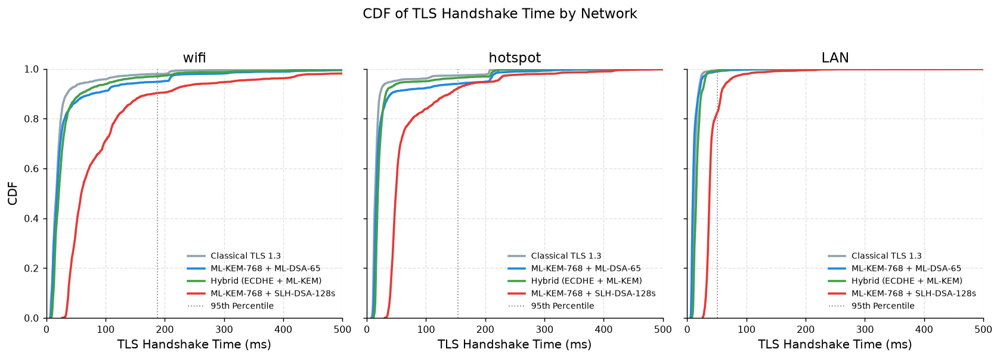

In [50]:
# =============================================================================
# CDF of TLS Handshake Time by Network
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

nets = ["wifi", "hotspot", "LAN"]

fig, axes = plt.subplots(
    1,
    len(nets),
    figsize=(13, 4.5),
    sharey=True
)

for ax, net in zip(axes, nets):

    sub_net = df_clean[df_clean[COL_NETWORK] == net]

    for cfg in CONFIG_ORDER:

        vals = np.sort(
            sub_net[
                sub_net[COL_CONFIGURATION] == cfg
            ][COL_TLS_TIME].values
        )

        if len(vals) == 0:
            continue

        cdf = np.arange(1, len(vals) + 1) / len(vals)

        ax.plot(
            vals,
            cdf,
            label=CONFIG_LABELS_FLAT[cfg],
            color=CONFIG_COLORS[cfg],
            linewidth=2
        )

    # Overall 95th percentile for the network
    if len(sub_net) > 0:

        p95 = np.percentile(
            sub_net[COL_TLS_TIME],
            95
        )

        ax.axvline(
            x=p95,
            linestyle=":",
            color="#888888",
            linewidth=1,
            label="95th Percentile"
        )

    # -------------------------------------------------------------------------
    # Axes
    # -------------------------------------------------------------------------

    ax.set_title(net)
    ax.set_xlabel("TLS Handshake Time (ms)")

    # Keep the same x-axis for all networks
    ax.set_xlim(0, 500)
    ax.set_xticks(np.arange(0, 501, 100))

    # Keep the same y-axis for all networks
    ax.set_ylim(0, 1.0)
    ax.set_yticks(np.linspace(0, 1, 6))

    ax.grid(
        linestyle="--",
        alpha=0.35
    )

    if ax is axes[0]:
        ax.set_ylabel("CDF")

    ax.legend(
        frameon=False,
        fontsize=7.5,
        loc="lower right"
    )

fig.suptitle(
    "CDF of TLS Handshake Time by Network",
    fontsize=13,
    y=1.02
)

plt.tight_layout()

save_plot(
    "cdf_tls_handshake_time_by_network.png",
    "combined"
)

plt.show()

# Handshake Payload vs. Transport Flight Thresholds

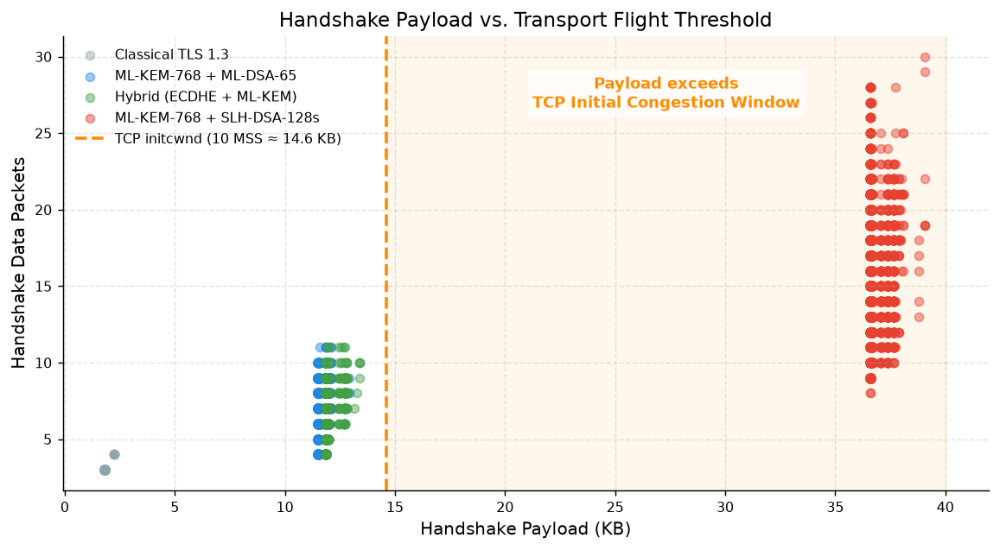

In [52]:
# =============================================================================
# Handshake Payload vs Transport Flight Threshold
# =============================================================================

fig, ax = plt.subplots(figsize=(9, 5))

# Plot each TLS configuration separately
for cfg in CONFIG_ORDER:

    subset = df_clean[df_clean[COL_CONFIGURATION] == cfg]

    ax.scatter(
        subset[COL_HANDSHAKE_KB],
        subset[COL_HANDSHAKE_DATA_PACKETS],
        s=30,
        alpha=0.45,
        color=CONFIG_COLORS[cfg],
        label=CONFIG_LABELS_FLAT[cfg]
    )

# =============================================================================
# TCP Initial Congestion Window (~10 MSS ≈ 14.6 KB)
# =============================================================================

INITCWND_KB = 14.6

ax.axvline(
    INITCWND_KB,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label="TCP initcwnd (10 MSS ≈ 14.6 KB)"
)

# Shade region beyond initcwnd
xmax = df_clean[COL_HANDSHAKE_KB].max() + 1

ax.axvspan(
    INITCWND_KB,
    xmax,
    color="orange",
    alpha=0.08
)

# Label the shaded region
ax.text(
    INITCWND_KB + (xmax - INITCWND_KB) / 2,
    df_clean[COL_HANDSHAKE_DATA_PACKETS].max() * 0.96,
    "Payload exceeds\nTCP Initial Congestion Window",
    color="darkorange",
    fontsize=10,
    fontweight="bold",
    ha="center",
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.75,
        pad=3
    )
)

# =============================================================================
# Labels
# =============================================================================

ax.set_xlabel("Handshake Payload (KB)")
ax.set_ylabel("Handshake Data Packets")
ax.set_title("Handshake Payload vs. Transport Flight Threshold")

ax.grid(True, linestyle="--", alpha=0.35)
ax.legend(frameon=False)

plt.tight_layout()

save_plot(
    "handshake_payload_vs_transport_threshold.png",
    "combined"
)

plt.show()

# Longitudinal Stability Timeline (ML-KEM + SLH-DSA)


Longitudinal Stability Summary

                          Mean   Median    Std    Min     Max      N    Q1      Q3      P95    IQR 
Week Label                                                                                         
3rd Week of May 2026     53.110  38.490  44.936 26.205  707.686  2391 35.118  47.838 136.077 12.720
3rd Week of July 2026    68.118  46.438  72.467 26.878  975.504  2388 39.546  61.846 156.012 22.300
4th Week of July 2026    70.793  47.784  90.379 28.787 1067.862  1595 40.716  63.924 154.994 23.208
5th Week of July 2026   106.506  60.992 102.927 35.394 1031.631  1198 53.125 120.629 302.324 67.504
1st Week of August 2026 121.372  49.562 153.392 30.604  944.298   299 38.710 136.603 429.763 97.893


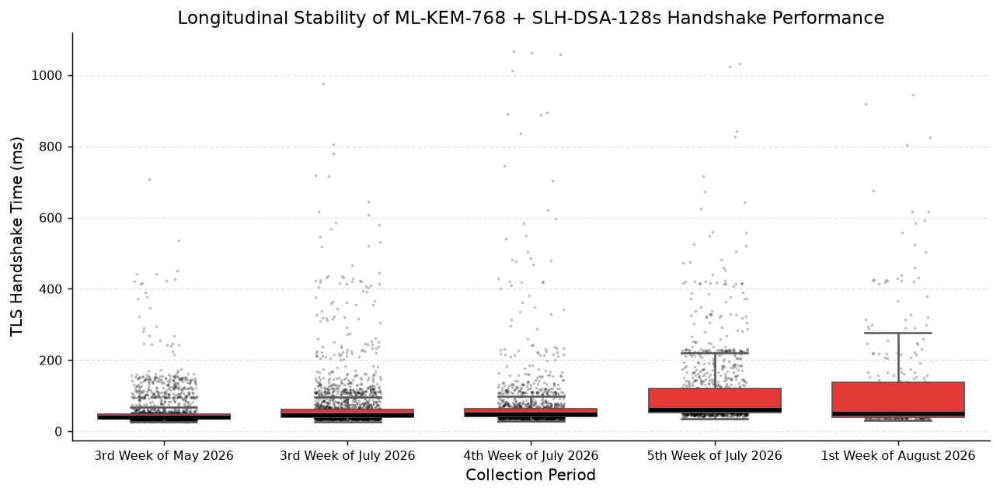

In [ ]:
# =============================================================================
# Longitudinal Stability Timeline
# (ML-KEM-768 + SLH-DSA-128s)
# =============================================================================


# -----------------------------------------------------------------------------
# Select Configuration
# -----------------------------------------------------------------------------

long_df = df_clean[
    df_clean[COL_CONFIGURATION] == "mlkem_slhdsa"
].copy()

# -----------------------------------------------------------------------------
# Convert Data Types
# -----------------------------------------------------------------------------

# Timestamp
long_df[COL_TIMESTAMP] = pd.to_datetime(
    long_df[COL_TIMESTAMP],
    errors="coerce"
)

# TLS Handshake Time -> Numeric
long_df[COL_TLS_TIME] = pd.to_numeric(
    long_df[COL_TLS_TIME],
    errors="coerce"
)

# Remove invalid rows
long_df = long_df.dropna(
    subset=[COL_TIMESTAMP, COL_TLS_TIME]
)

# -----------------------------------------------------------------------------
# Create Batch IDs
# (Each unique collection date = one batch)
# -----------------------------------------------------------------------------

long_df["batch"] = (
    long_df[COL_TIMESTAMP]
    .dt.normalize()
    .rank(method="dense")
    .astype(int)
)

# -----------------------------------------------------------------------------
# Every 2 batches = 1 Week
# -----------------------------------------------------------------------------

long_df["week"] = (
    (long_df["batch"] - 1) // 2
) + 1

# =============================================================================
# CUSTOM WEEK LABELS
# =============================================================================

WEEK_LABELS = {
    1: "3rd Week of May 2026",
    2: "3rd Week of July 2026",
    3: "4th Week of July 2026",
    4: "5th Week of July 2026",
    5: "1st Week of August 2026",
    6: "Week 6",
    7: "Week 7",
    8: "Week 8",
    9: "Week 9",
    10: "Week 10",
    11: "Week 11"
}

# -----------------------------------------------------------------------------
# Map Labels
# -----------------------------------------------------------------------------

long_df["Week Label"] = long_df["week"].map(WEEK_LABELS)

# Remove any weeks without labels
long_df = long_df.dropna(subset=["Week Label"])

week_order = [
    WEEK_LABELS[w]
    for w in sorted(long_df["week"].unique())
]

# =============================================================================
# Statistical Summary
# =============================================================================

grouped = long_df.groupby("Week Label")[COL_TLS_TIME]

summary = grouped.agg(
    Mean="mean",
    Median="median",
    Std="std",
    Min="min",
    Max="max",
    N="count"
)

summary["Q1"] = grouped.quantile(0.25)
summary["Q3"] = grouped.quantile(0.75)
summary["P95"] = grouped.quantile(0.95)
summary["IQR"] = summary["Q3"] - summary["Q1"]

summary = summary.loc[week_order]

print("\nLongitudinal Stability Summary\n")
print(
    summary.round(3).to_string(
        justify="center",
        float_format=lambda x: f"{x:.3f}"
    )
)

# =============================================================================
# Plot
# =============================================================================

plt.figure(figsize=(10, 5))

# Scatter points
sns.stripplot(
    data=long_df,
    x="Week Label",
    y=COL_TLS_TIME,
    order=week_order,
    color="black",
    alpha=0.25,
    size=2,
    jitter=0.18,
    zorder=1
)

# Boxplots
sns.boxplot(
    data=long_df,
    x="Week Label",
    y=COL_TLS_TIME,
    order=week_order,
    color=CONFIG_COLORS["mlkem_slhdsa"],
    width=0.72,
    showfliers=False,
    saturation=1,
    boxprops=dict(zorder=3),
    whiskerprops=dict(zorder=3, linewidth=1.4),
    capprops=dict(zorder=3, linewidth=1.4),
    medianprops=dict(
        color="black",
        linewidth=2.8,
        zorder=4
    )
)

plt.title(
    "Longitudinal Stability of ML-KEM-768 + SLH-DSA-128s Handshake Performance"
)

plt.xlabel("Collection Period")
plt.ylabel("TLS Handshake Time (ms)")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)

plt.tight_layout()

save_plot(
    "longitudinal_stability_timeline.png",
    "combined"
)

plt.show()